<a href="https://colab.research.google.com/github/jostina/Netflix-Dataset/blob/main/Cleaned_Netflix_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Task 2: Netflix Exploratory Data Analysis (EDA)

Step 1: Import libraries and load the cleaned dataset

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the cleaned Netflix dataset
df = pd.read_csv("/content/netflix_titles_cleaned.csv")

# Display the first five rows
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,date_added_year,date_added_month,date_added_month_name,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9,September,90,min
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9,September,1,Season
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9,September,1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9,September,91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9,September,125,min


Step 2: Analyze dataset structure and statistics

In [2]:
# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Generate descriptive statistics
df.describe(include="all").T

Dataset shape: (8790, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   show_id                8790 non-null   object
 1   type                   8790 non-null   object
 2   title                  8790 non-null   object
 3   director               8790 non-null   object
 4   country                8790 non-null   object
 5   date_added             8790 non-null   object
 6   release_year           8790 non-null   int64 
 7   rating                 8790 non-null   object
 8   duration               8790 non-null   object
 9   listed_in              8790 non-null   object
 10  date_added_year        8790 non-null   int64 
 11  date_added_month       8790 non-null   int64 
 12  date_added_month_name  8790 non-null   object
 13  duration_value         8790 non-null   int64 
 14  duration_unit          8790 non-null   object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8790,8790,s8786,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8790,2,Movie,6126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8790,8786,9-Feb,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8790,4528,Not Given,2588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8790,86,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8790,1713,2020-01-01,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8790.0,NaN,NaN,NaN,2014.183163,8.825466,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8790,14,TV-MA,3205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8790,220,1 Season,1791,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8790,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Display column names
print("\nColumns:", df.columns.tolist())

Missing values per column:
show_id                  0
type                     0
title                    0
director                 0
country                  0
date_added               0
release_year             0
rating                   0
duration                 0
listed_in                0
date_added_year          0
date_added_month         0
date_added_month_name    0
duration_value           0
duration_unit            0
dtype: int64
Duplicate rows: 0

Columns: ['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'date_added_year', 'date_added_month', 'date_added_month_name', 'duration_value', 'duration_unit']


Step 3: Study content distribution by type
Compare the number of movies and TV shows.

In [4]:
# Count content by type
type_counts = df["type"].value_counts()

print(type_counts)

# Calculate percentages
type_percentages = df["type"].value_counts(normalize=True).mul(100).round(2)
print("\nContent distribution (%):")
print(type_percentages)

type
Movie      6126
Tv Show    2664
Name: count, dtype: int64

Content distribution (%):
type
Movie      69.69
Tv Show    30.31
Name: proportion, dtype: float64


Visualize the distribution:

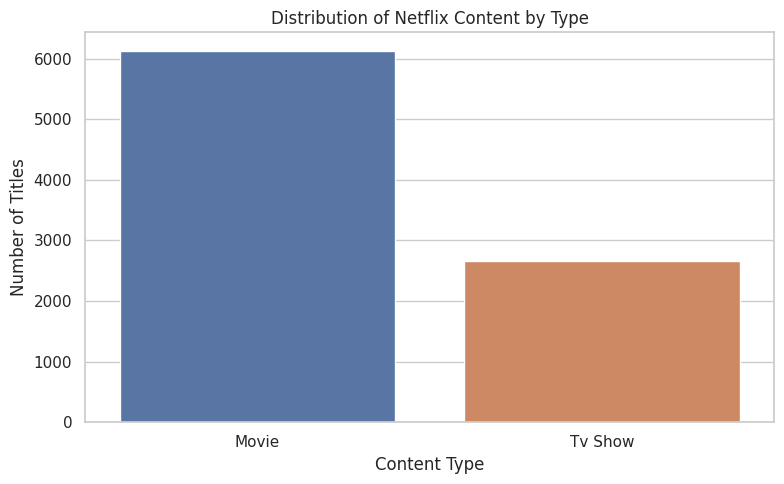

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="type", hue="type", legend=False)

plt.title("Distribution of Netflix Content by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

Step 4: Identify the top countries

In [6]:
# Split multiple countries into separate rows
countries = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
)

# Count the top 10 countries
top_countries = countries.value_counts().head(10)

print(top_countries)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


Visualize the results:

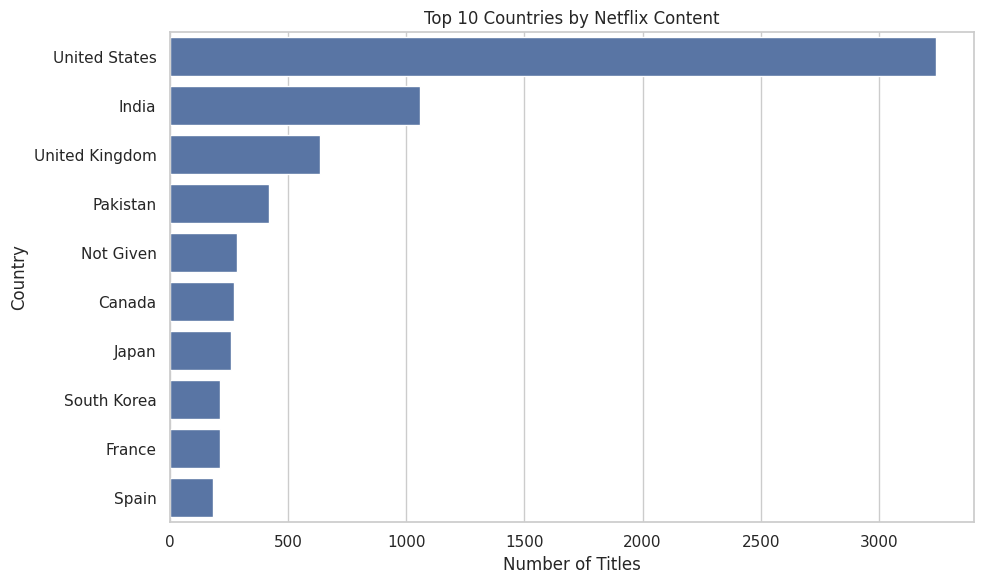

In [7]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Step 5: Identify the top genres and categories

In [8]:
# Split multiple genres into separate rows
genres = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
)

# Find the top 10 genres
top_genres = genres.value_counts().head(10)

print(top_genres)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


Create a visualization

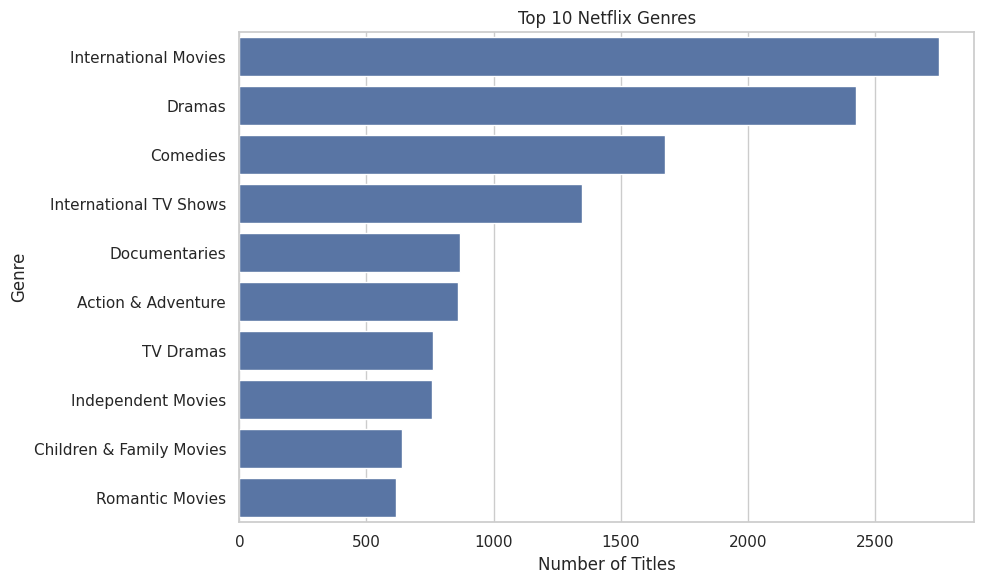

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

Step 6: Analyze content trends over time
Examine how Netflix content varies by release year.

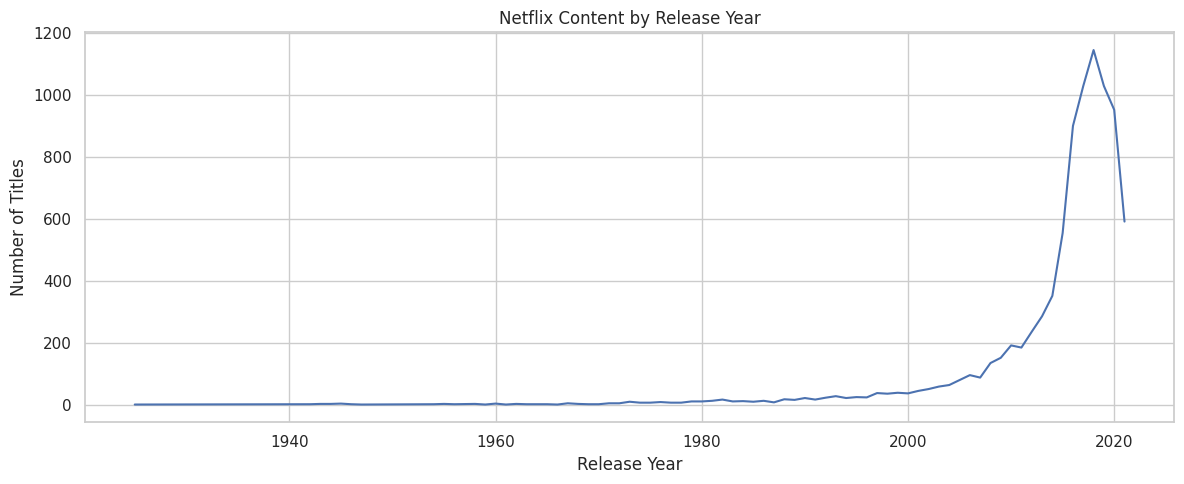

In [10]:
# Convert release_year to numeric
df["release_year"] = pd.to_numeric(
    df["release_year"],
    errors="coerce"
)

# Count titles by release year
yearly_counts = (
    df.dropna(subset=["release_year"])
    .groupby("release_year")
    .size()
    .sort_index()
)

# Plot release-year trends
plt.figure(figsize=(12, 5))

yearly_counts.plot(kind="line")

plt.title("Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

To make recent trends easier to read, focus on titles released from 2000 onward:

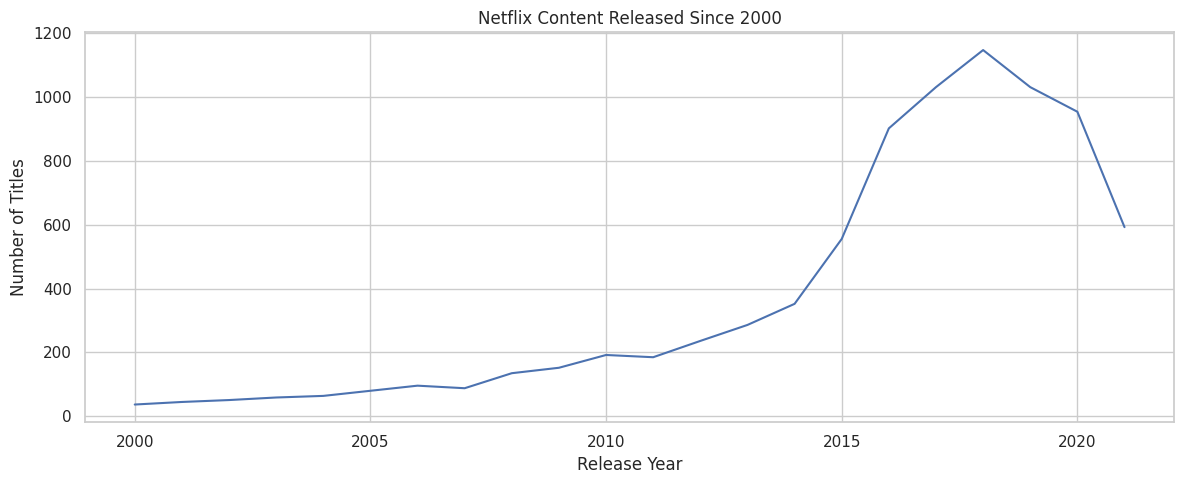

In [11]:
recent_yearly_counts = yearly_counts.loc[yearly_counts.index >= 2000]

plt.figure(figsize=(12, 5))

recent_yearly_counts.plot(kind="line")

plt.title("Netflix Content Released Since 2000")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

Step 7: Compare movies and TV shows over time

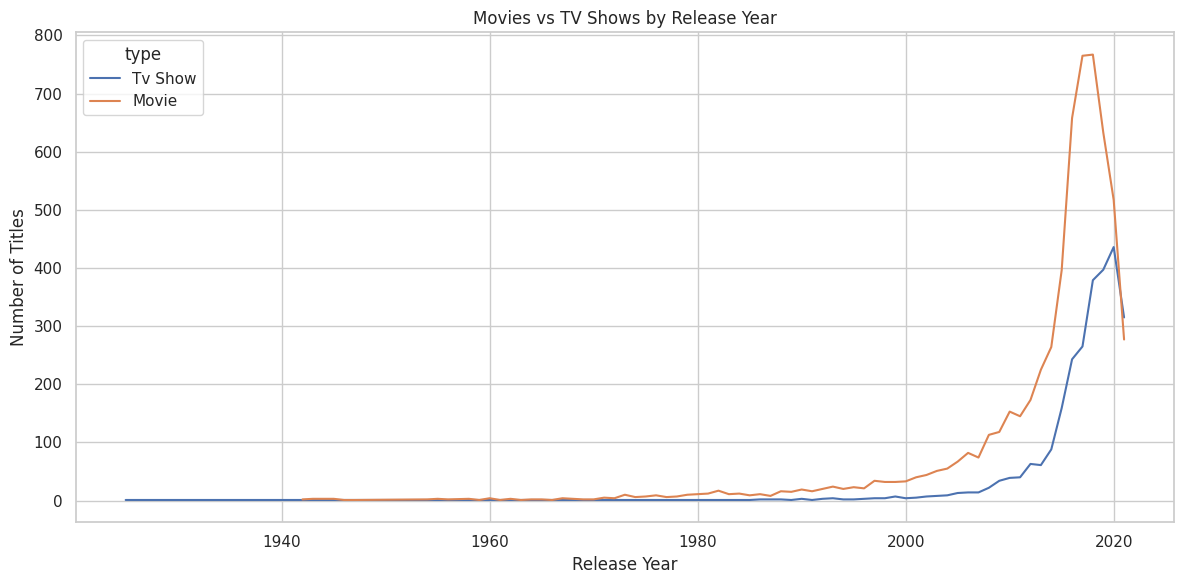

In [12]:
type_year_counts = (
    df.dropna(subset=["release_year"])
    .groupby(["release_year", "type"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=type_year_counts,
    x="release_year",
    y="count",
    hue="type"
)

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

Step 8: Analyze movie duration

In [13]:
# Extract movie duration in minutes
movie_duration = pd.to_numeric(
    df.loc[df["type"] == "Movie", "duration"]
    .astype("string")
    .str.extract(r"(\d+)")[0],
    errors="coerce"
)

print(movie_duration.describe())

count       6126.0
mean     99.584884
std      28.283225
min            3.0
25%           87.0
50%           98.0
75%          114.0
max          312.0
Name: 0, dtype: Float64


Visualize the distribution

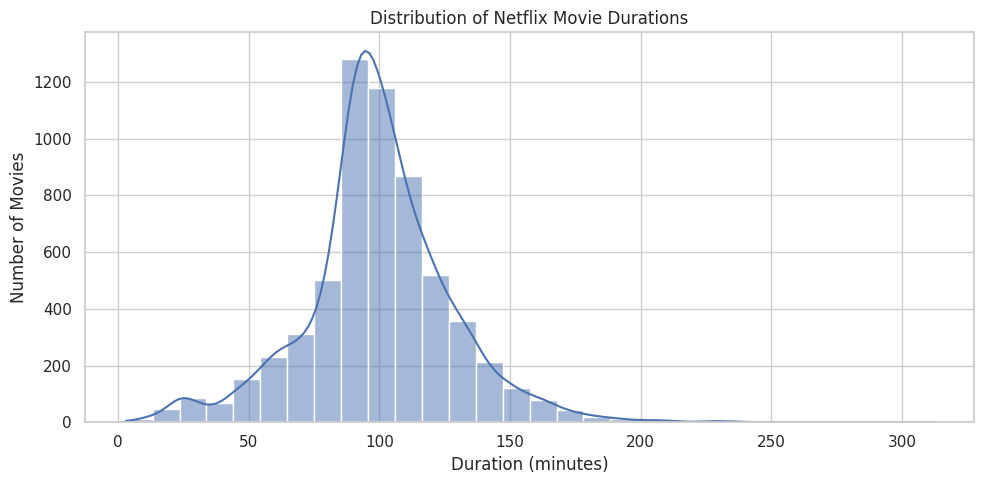

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(movie_duration.dropna(), bins=30, kde=True)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

Step 9: Summarize the findings

In [15]:
# Content type distribution
type_counts = df["type"].value_counts()
type_percentages = df["type"].value_counts(normalize=True).mul(100)

print("NETFLIX EDA SUMMARY")
print("=" * 40)

print(f"Total titles: {len(df):,}")
print(f"Total columns: {df.shape[1]}")

print("\nContent by type:")
for content_type, count in type_counts.items():
    print(
        f"{content_type}: {count:,} "
        f"({type_percentages[content_type]:.2f}%)"
    )

# Most frequent country
if "country" in df.columns and countries.size > 0:
    print("\nTop 5 countries:")
    print(countries.value_counts().head(5))

# Most frequent genre
if "listed_in" in df.columns and genres.size > 0:
    print("\nTop 5 genres:")
    print(genres.value_counts().head(5))

# Release-year statistics
if "release_year" in df.columns:
    print("\nRelease year statistics:")
    print(df["release_year"].describe())

NETFLIX EDA SUMMARY
Total titles: 8,790
Total columns: 15

Content by type:
Movie: 6,126 (69.69%)
Tv Show: 2,664 (30.31%)

Top 5 countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

Top 5 genres:
listed_in
International Movies      2752
Dramas                    2426
Comedies                  1674
International TV Shows    1349
Documentaries              869
Name: count, dtype: int64

Release year statistics:
count    8790.000000
mean     2014.183163
std         8.825466
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64


In [16]:
movie_duration = pd.to_numeric(
    df.loc[df["type"] == "Movie", "duration"]
      .astype("string")
      .str.extract(r"(\d+)")[0],
    errors="coerce"
)

print("Median movie duration:", movie_duration.median(), "minutes")

Median movie duration: 98.0 minutes


# Netflix Dataset: Exploratory Data Analysis

## Objective

The objective of this analysis was to explore the cleaned Netflix dataset, understand its structure, identify content distribution patterns, determine the leading countries and genres, and examine trends in release years.

## Key Findings

1. **Content distribution:** The dataset contains 6,126 movies (69.69%) and 2,664 TV shows (30.31%), making movies the largest share of the content.

2. **Top countries:** The United States contributes the most titles, with 3,240, followed by India with 1,057, the United Kingdom with 638, and Pakistan with 421. An additional 287 titles have their country recorded as "Not Given".

3. **Popular genres:** The most frequently listed categories are International Movies (2,752), Dramas (2,426), Comedies (1,674), International TV Shows (1,349), and Documentaries (869). These results highlight the prominence of international content, drama, and comedy in the dataset.

4. **Release-year trends:** The release-year analysis shows that the dataset is concentrated around relatively recent releases. The median release year is 2017, while the middle 50% of titles were released between 2013 and 2019. The dataset covers releases from 1925 to 2021. These figures describe the original release years of the titles rather than the dates they were added to Netflix.

5. **Movie duration:** Movie duration was 98.0 minutes.

## Conclusion

The exploratory data analysis examined 8,790 Netflix titles across 15 columns. Data quality checks confirmed that the cleaned dataset contained no missing values or duplicate rows.

The findings show that movies account for 69.69% of the dataset, compared with 30.31% for TV shows. The United States is the most represented country, while International Movies, Dramas, and Comedies are the most frequently listed categories. The release-year statistics indicate that many titles were released between 2013 and 2019.

Overall, this project demonstrated the use of Python, Pandas, Matplotlib, and Seaborn for data exploration, descriptive statistics, and visualization. The findings provide a foundation for further analysis, including comparisons between movies and TV shows, genre distribution by country, and trends in content releases over time.